In [1]:
#proto mechanixm for the random seed
import random 
first_two_pixel_value=10
random.seed(first_two_pixel_value)
num_of_pixels=10 
rando_list = [i for i in range(num_of_pixels)]
random.Random(first_two_pixel_value).shuffle(rando_list)
rando_list

[5, 2, 7, 1, 8, 4, 3, 6, 0, 9]

In [2]:
#file imports used
from PIL import Image
from matplotlib import pyplot as plt
import math
import codecs

In [3]:
number_of_bits = 1
#open a bmp and get its size
x = Image.open("stego.bmp")
pic_size = x.size
num_of_pixels = x.size[0]*x.size[1]
print(num_of_pixels)
available_bytes=(num_of_pixels*(number_of_bits*3))/8
print(available_bytes,"bytes")

1091840
409440.0 bytes


In [4]:
#value of the first two pixels 
firstpixel = x.getpixel((0,0))
secondpixel = x.getpixel((0,1))

In [5]:
# proto mechanism for generating a seed from first two pixels
seed = math.floor((sum(firstpixel)/3+sum(secondpixel)/3)/2)

In [6]:
#Text file to binary and back
fileName="test_message.txt"
with open(fileName, mode='r') as file:
    fileContent = file.read()
print(fileContent)
res = ''.join(format(ord(i), '08b') for i in fileContent)
print(res)
ans = []
for i in range(0, len(res), 8):
    ans.append(chr(int(res[i:i+8],2)))
output = ''.join(ans)
output

This is a test message.  Hopefully this can get hidden in a file and come out intact on the other side.
01010100011010000110100101110011001000000110100101110011001000000110000100100000011101000110010101110011011101000010000001101101011001010111001101110011011000010110011101100101001011100010000000100000010010000110111101110000011001010110011001110101011011000110110001111001001000000111010001101000011010010111001100100000011000110110000101101110001000000110011101100101011101000010000001101000011010010110010001100100011001010110111000100000011010010110111000100000011000010010000001100110011010010110110001100101001000000110000101101110011001000010000001100011011011110110110101100101001000000110111101110101011101000010000001101001011011100111010001100001011000110111010000100000011011110110111000100000011101000110100001100101001000000110111101110100011010000110010101110010001000000111001101101001011001000110010100101110


'This is a test message.  Hopefully this can get hidden in a file and come out intact on the other side.'

In [7]:

class BitFeederString:
    """This class will take a file_name and convert it into string-based bits
    that can be extracted in small pieces.
    
    example syntax:
    bfeed = BitFeederString(my_message_file)
    first_three_bits = bfeed.get_bits(3)
    next_three_bits = bfeed.get_bits(3)
    following_two bits = bfeed.get_bits(2)
    """

    def __init__(self, file_name):       
        self.file_name = file_name
        self._load_bytes()
        self._make_bitstring()
        self.index = 0
        self.finished = False

    def _load_bytes(self):
        with open(self.file_name, 'rb') as in_file:
            self.bytes = in_file.read()

    def _make_bitstring(self):
        bitsarray = []
        for byte in self.bytes:
            bits = bin(byte)[2:]
            bits = '0'*(8-len(bits)) + bits
            bitsarray.append(bits)
        self.bitstring = ''.join(bitsarray)
    
    def get_length(self):
        return(len(self.bitstring))

    def get_bits(self, n, returntype=str):
        """this function returns n bits 
            
            x = bitfeederobj.get_bits(6, returntype=str)
            print(x)

            '101110'

            x = bitfeederobj.get_bits(6, returntype=int)
            print(x)

            46

        Args:
            n (int): Number of bits requested back
            returntype (type): The requested data return type. 
                Currently supports str and intDefaults to str.
                


        Returns:
            str: bit data
            or 
            int: bit data
            (return type depends on input parameter)
        """        
        start = self.index
        self.index += n
        if self.index < len(self.bitstring):
            r = self.bitstring[start:self.index]

        else:
            r = self.bitstring[start:]
            self.finished=True

        if returntype == int:
            return int(r, 2)
        return r

In [8]:
bfeed = BitFeederString("test_message.txt")
length = bfeed.get_length()
length

824

In [9]:
#Makes sure we have an 8 bit byte from int
def byte_maker(color):
    return f'{color:08b}'
#returns an int from byte bin string
def int_maker(color):
    return int(color, 2)
#encodes however many bits specified
def encoder(cover,message,bits):
    return cover[:-bits]+message

#PIXELS ENCODED
for i in range(pic_size[0]):
    for j in range(pic_size[1]):
        color = x.getpixel((i,j))
        modified = []
        print("OG"+str(color))
        for RGB in range(len(color)):
                input = color[RGB]
                #print(str(input))
                cover = byte_maker(input)
                #print(cover)
                message = bfeed.get_bits(1)
                #print(message)
                encoded = encoder(cover,message,1)
                #print(encoded)
                output = int(encoded, 2)
                #print(output)
                modified.append(output)
        x.putpixel( (i , j), (modified[0], modified[1], modified[2], 255))
        print("MOD"+x.getpixel((i,j)))
        if bfeed.finished == True:
            break

OG(178, 132, 145)
(178, 133, 144)
OG(170, 124, 137)
(171, 124, 137)
OG(182, 134, 148)
(182, 134, 148)
OG(180, 132, 146)
(181, 133, 146)
OG(181, 133, 147)
(181, 132, 146)
OG(186, 138, 152)
(186, 138, 153)
OG(175, 127, 143)
(175, 126, 143)
OG(184, 136, 152)
(184, 136, 153)
OG(185, 134, 151)
(184, 135, 151)
OG(183, 132, 149)
(183, 132, 148)
OG(179, 128, 145)
(179, 129, 144)
OG(178, 127, 144)
(178, 127, 144)
OG(172, 121, 138)
(172, 120, 138)
OG(178, 127, 144)
(178, 126, 145)
OG(181, 130, 149)
(181, 130, 149)
OG(182, 131, 150)
(182, 130, 151)
OG(181, 133, 149)
(180, 133, 149)
OG(176, 129, 145)
(177, 128, 144)
OG(180, 133, 149)
(181, 133, 148)
OG(176, 129, 145)
(176, 129, 144)
OG(177, 130, 146)
(176, 130, 146)
OG(180, 133, 149)
(180, 132, 149)
OG(175, 128, 144)
(175, 128, 144)
OG(178, 131, 147)
(178, 130, 147)
OG(174, 126, 142)
(174, 126, 143)
OG(181, 133, 149)
(180, 132, 148)
OG(185, 137, 153)
(184, 136, 152)
OG(181, 133, 149)
(181, 133, 149)
OG(178, 130, 146)
(178, 131, 146)
OG(180, 132, 1

OG(72, 53, 75)
(36, 26, 37)
OG(67, 48, 70)
(33, 24, 35)
OG(71, 52, 74)
(35, 26, 37)
OG(73, 54, 76)
(36, 27, 38)
OG(69, 51, 73)
(34, 25, 36)
OG(70, 52, 74)
(35, 26, 37)
OG(71, 53, 75)
(35, 26, 37)
OG(71, 53, 75)
(35, 26, 37)
OG(69, 51, 73)
(34, 25, 36)
OG(69, 51, 73)
(34, 25, 36)
OG(71, 53, 75)
(35, 26, 37)
OG(73, 55, 77)
(36, 27, 38)
OG(69, 51, 73)
(34, 25, 36)
OG(69, 51, 73)
(34, 25, 36)
OG(78, 60, 82)
(39, 30, 41)
OG(70, 52, 74)
(35, 26, 37)
OG(75, 57, 79)
(37, 28, 39)
OG(66, 48, 70)
(33, 24, 35)
OG(72, 54, 76)
(36, 27, 38)
OG(71, 54, 73)
(35, 27, 36)
OG(76, 59, 78)
(38, 29, 39)
OG(74, 57, 75)
(37, 28, 37)
OG(72, 55, 73)
(36, 27, 36)
OG(70, 53, 71)
(35, 26, 35)
OG(70, 53, 71)
(35, 26, 35)
OG(71, 54, 72)
(35, 27, 36)
OG(70, 53, 72)
(35, 26, 36)
OG(70, 53, 72)
(35, 26, 36)
OG(70, 53, 72)
(35, 26, 36)
OG(72, 55, 74)
(36, 27, 37)
OG(70, 53, 72)
(35, 26, 36)
OG(69, 52, 71)
(34, 26, 35)
OG(78, 60, 82)
(39, 30, 41)
OG(64, 46, 68)
(32, 23, 34)
OG(75, 57, 79)
(37, 28, 39)
OG(64, 46, 68)
(32, 

(36, 26, 39)
OG(75, 55, 80)
(37, 27, 40)
OG(76, 56, 81)
(38, 28, 40)
OG(77, 57, 84)
(38, 28, 42)
OG(76, 56, 83)
(38, 28, 41)
OG(74, 56, 82)
(37, 28, 41)
OG(73, 55, 81)
(36, 27, 40)
OG(73, 55, 81)
(36, 27, 40)
OG(79, 61, 87)
(39, 30, 43)
OG(73, 57, 83)
(36, 28, 41)
OG(72, 56, 82)
(36, 28, 41)
OG(75, 59, 86)
(37, 29, 43)
OG(70, 54, 81)
(35, 27, 40)
OG(66, 52, 78)
(33, 26, 39)
OG(76, 62, 88)
(38, 31, 44)
OG(77, 59, 85)
(38, 29, 42)
OG(75, 57, 83)
(37, 28, 41)
OG(72, 54, 80)
(36, 27, 40)
OG(74, 56, 82)
(37, 28, 41)
OG(78, 60, 86)
(39, 30, 43)
OG(79, 61, 87)
(39, 30, 43)
OG(78, 60, 86)
(39, 30, 43)
OG(76, 58, 84)
(38, 29, 42)
OG(86, 68, 94)
(43, 34, 47)
OG(72, 54, 80)
(36, 27, 40)
OG(74, 56, 82)
(37, 28, 41)
OG(75, 57, 83)
(37, 28, 41)
OG(74, 56, 82)
(37, 28, 41)
OG(75, 57, 83)
(37, 28, 41)
OG(79, 61, 87)
(39, 30, 43)
OG(68, 50, 76)
(34, 25, 38)
OG(77, 59, 85)
(38, 29, 42)
OG(74, 56, 82)
(37, 28, 41)
OG(72, 54, 80)
(36, 27, 40)
OG(72, 54, 80)
(36, 27, 40)
OG(74, 56, 82)
(37, 28, 41)
OG(75, 

(44, 32, 48)
OG(94, 70, 102)
(47, 35, 51)
OG(91, 67, 101)
(45, 33, 50)
OG(98, 74, 108)
(49, 37, 54)
OG(98, 74, 108)
(49, 37, 54)
OG(97, 73, 107)
(48, 36, 53)
OG(97, 73, 107)
(48, 36, 53)
OG(96, 72, 106)
(48, 36, 53)
OG(95, 71, 107)
(47, 35, 53)
OG(95, 71, 107)
(47, 35, 53)
OG(95, 71, 107)
(47, 35, 53)
OG(95, 71, 105)
(47, 35, 52)
OG(101, 74, 107)
(50, 37, 53)
OG(96, 69, 100)
(48, 34, 50)
OG(91, 64, 97)
(45, 32, 48)
OG(101, 74, 107)
(50, 37, 53)
OG(90, 63, 96)
(45, 31, 48)
OG(98, 71, 104)
(49, 35, 52)
OG(96, 69, 102)
(48, 34, 51)
OG(100, 73, 106)
(50, 36, 53)
OG(101, 74, 109)
(50, 37, 54)
OG(96, 69, 104)
(48, 34, 52)
OG(99, 72, 107)
(49, 36, 53)
OG(106, 79, 114)
(53, 39, 57)
OG(104, 77, 112)
(52, 38, 56)
OG(99, 72, 107)
(49, 36, 53)
OG(98, 71, 106)
(49, 35, 53)
OG(96, 69, 104)
(48, 34, 52)
OG(99, 73, 110)
(49, 36, 55)
OG(100, 74, 111)
(50, 37, 55)
OG(96, 72, 108)
(48, 36, 54)
OG(96, 72, 108)
(48, 36, 54)
OG(99, 75, 111)
(49, 37, 55)
OG(101, 77, 113)
(50, 38, 56)
OG(116, 92, 128)
(58, 46

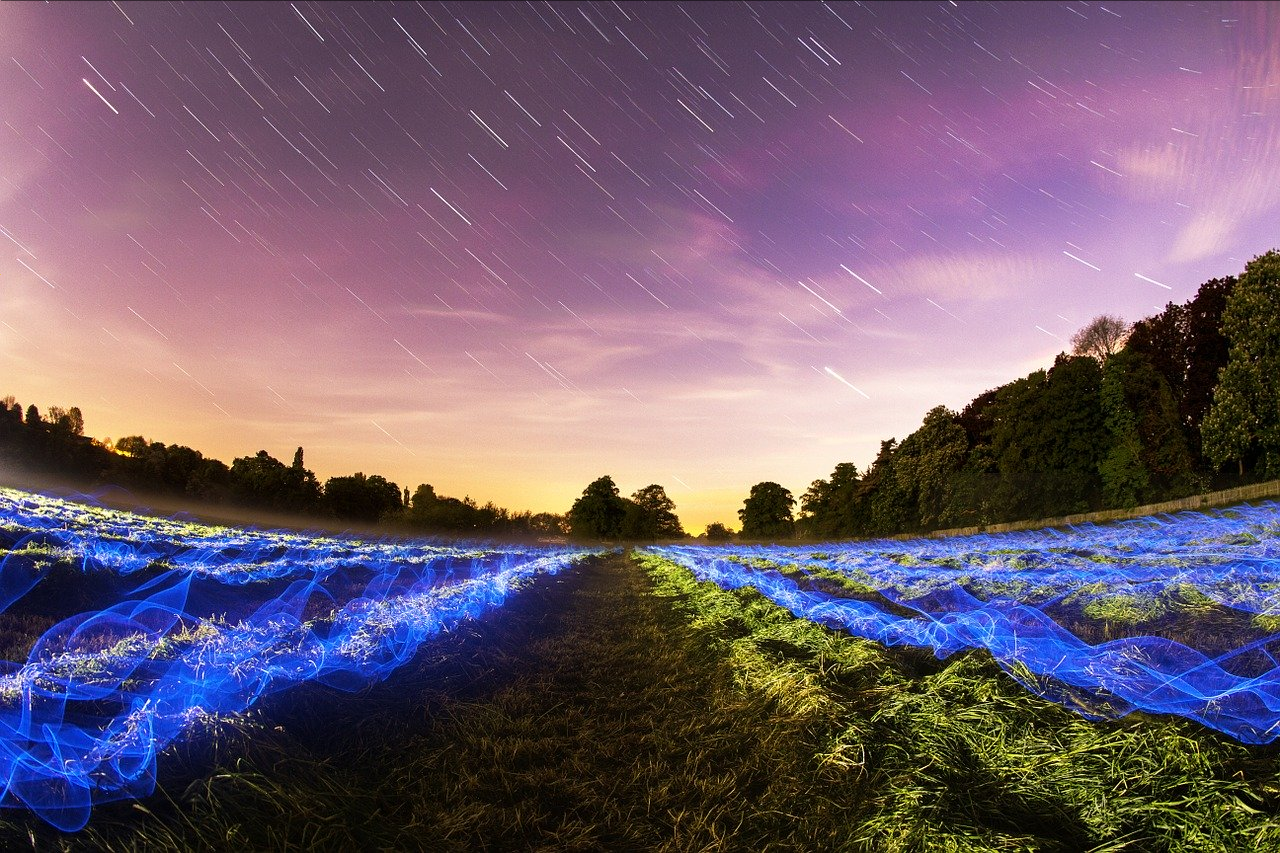

In [10]:
x